# Control analysis
**Authors:**
- Nora Constanze Laubach
- Behnam Yousefi

In [68]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm

In [69]:
def statistics(x):

    x = np.array(x)                   # converts one col table to list

    # Non parametric statistics
    median = np.median(x)
    Q1 = np.percentile(x, 25)
    Q3 = np.percentile(x, 75)
    IQR = Q3 - Q1
    IQR_rel = IQR/median*100
    # x_filtered = x[(x >= (Q1 - 1.5*IQR)) &  (x <= (Q3 + 1.5*IQR))]    # filter x values outside [Q1 - 1.5*IQR , Q3 + 1.5*IQ]
    # median_filtered = np.median(x_filtered)                           # calculate median again without outliers (however, median is already robust)

   # Parametric statistics
    mean = np.mean(x)
    sd = np.std(x)
    thr = 3               # 3 sigma
    z = (x - mean) / sd
    x_filtered = x[(z >= -thr) &  (z <= thr)]
    mean_filtered = np.mean(x_filtered)
    sd_filtered = np.std(x_filtered)

    stats = {
        'median' : median.item(),
        'iqr' : IQR.item(),
        'iqr_rel' : IQR_rel.item(),
        'mean' : mean_filtered.item(),      # mean is mean after 3 sigma filtering
        'sd' : sd_filtered.item(),
    }

    return stats

In [70]:
# Read PO table
df = pd.read_excel("PO-ini2810.xlsx")
df.shape    # only for control while programming, shows number of (rows, columns)
# df

(176000, 20)

In [71]:
# get the df of DMSO as the negative control
df_DMSO = df.loc[df['ID'] == 'DMSO']
uniq_Plate_IDs = df_DMSO['Plate_ID'].unique()

In [72]:
# Create df_tsa_ctrl
# each row corresponds a plate
# cols: tsa/spsh + statistics

columns_table = ['Plate_ID', 'Protein', 'Compound'] + [f'Rep{i}' for i in range(1, 17)] + ['Median', 'IQR', 'IQR_rel[%]', 'Mean', 'STD']
df_tsa_ctrl = pd.DataFrame(columns = columns_table)    #creates empty table with specified columns

# Loop over uniq_Plate_IDs
for i in tqdm(range(len(uniq_Plate_IDs))):
    
    plate_ID = uniq_Plate_IDs[i]
    protein = df.loc[df['Plate_ID'] == plate_ID, 'Protein'].unique().item()
    compound = 'DMSO'

    # Get control values for TSA
    df_temp = df.loc[(df['ID'] == compound) & (df['Plate_ID'] == plate_ID)].copy()    # creates a subset of df, where additionally only one Plate ID is shown  ()&()
    df_temp = df_temp.dropna(subset = ['Thermal_Shift'])                              # discards all lines where Thermal Shift is NaN
    
    tm = df_temp['Thermal_Shift'].tolist()       # creates a one column table and then converts to list
    if len(tm):
        stats = statistics(tm)
        newline = [plate_ID, protein, compound] + tm + list(stats.values())     
        df_tsa_ctrl.loc[len(df_tsa_ctrl)] = newline          # len(df) is number of existing lines; here, "newline" is added at the end of the table

100%|██████████████████████████████████████████████████████████████████████| 500/500 [00:05<00:00, 90.13it/s]


In [73]:
# Create df_spsh_ctrl
# each row corresponds a plate
# cols: tsa/spsh + statistics

columns_table = ['Plate_ID', 'Protein', 'Compound'] + [f'Rep{i}' for i in range(1, 17)] + ['Median', 'IQR', 'IQR_rel[%]', 'Mean', 'STD']
df_spsh_ctrl = pd.DataFrame(columns = columns_table)

# Loop over uniq_Plate_IDs
for i in tqdm(range(len(uniq_Plate_IDs))):
    
    plate_ID = uniq_Plate_IDs[i]
    protein = df.loc[df['Plate_ID'] == plate_ID, 'Protein'].unique().item()
    compound = 'DMSO'

    # Get control values for TSA
    df_temp = df.loc[(df['ID'] == compound) & (df['Plate_ID'] == plate_ID)].copy()    # creates a subset of df, where additionally only one Plate ID is shown  ()&()
    df_temp = df_temp.dropna(subset = ['Spectral_Shift'])                              # discards all lines where Thermal Shift is NaN
    
    tm = df_temp['Spectral_Shift'].tolist()       # creates a one column table and then converts to list
    if len(tm):
        stats = statistics(tm)
        newline = [plate_ID, protein, compound] + tm + list(stats.values())     
        df_spsh_ctrl.loc[len(df_spsh_ctrl)] = newline          # len(df) is number of existing lines; here, "newline" is added at the end of the table

100%|██████████████████████████████████████████████████████████████████████| 500/500 [00:05<00:00, 94.43it/s]


In [74]:
# Calculate delta_Tm
# Produce warnings
# Add entities to the PO table

df['delta_Tm_median'] = None
df['delta_Tm_mean'] = None
df['Tm_Warning'] = None

for i in tqdm(range(len(df))):

    Thermal_Shift = df.loc[i, 'Thermal_Shift']
    Plate_ID = df.loc[i, 'Plate_ID']

    df_tmp = df_tsa_ctrl.loc[df_tsa_ctrl['Plate_ID'] == Plate_ID]
    Median_DMSO = df_tmp['Median']
    Mean_DMSO = df_tmp['Mean']
    IQR_rel_DMSO = df_tmp['IQR_rel[%]']
    
    if Median_DMSO.empty or Mean_DMSO.empty:
        continue
        
    deltaTm_median = Thermal_Shift - Median_DMSO
    deltaTm_mean = Thermal_Shift - Mean_DMSO

    df.loc[i, 'delta_Tm_median'] = deltaTm_median.item()
    df.loc[i, 'delta_Tm_mean'] = deltaTm_mean.item()  

    # Make warnings
    warning = ''
    if IQR_rel_DMSO.item() >1:
        warning = warning + ' Warning: high Tm IQR for DMSO controls!'
    if Median_DMSO.item() <48.7:                                                     ######### THIS VALUE IS ONLY TRUE FOR PAH WT !!!!!    
        warning = warning + ' Warning: low Tm for DMSO controls!'
    df.loc[i, 'Tm_Warning'] = warning

100%|██████████████████████████████████████████████████████████████| 176000/176000 [00:42<00:00, 4109.38it/s]


In [75]:
# Calculate delta_SpSh
# Produce warnings
# Add entities to the PO table

df['delta_SpSh_median'] = None
df['delta_SpSh_mean'] = None
df['SpSh_Warning'] = None

for i in tqdm(range(len(df))):

    Spectral_Shift = df.loc[i, 'Spectral_Shift']
    Plate_ID = df.loc[i, 'Plate_ID']

    df_tmp = df_spsh_ctrl.loc[df_spsh_ctrl['Plate_ID'] == Plate_ID]
    Median_DMSO = df_tmp['Median']
    Mean_DMSO = df_tmp['Mean']
    IQR_rel_DMSO = df_tmp['IQR_rel[%]']
    
    if Median_DMSO.empty or Mean_DMSO.empty:
        continue
        
    deltaS_median = Spectral_Shift - Median_DMSO
    deltaS_mean = Spectral_Shift - Mean_DMSO

    df.loc[i, 'delta_SpSh_median'] = deltaS_median.item()
    df.loc[i, 'delta_SpSh_mean'] = deltaS_mean.item()  

    # Make warnings
    warning = ''
    if IQR_rel_DMSO.item() > 1.2:                                                         #### Behnam & Conny find better threshold together
        warning = warning + ' Warning: high SpSh IQR for DMSO controls!'
    df.loc[i, 'SpSh_Warning'] = warning

100%|██████████████████████████████████████████████████████████████| 176000/176000 [00:45<00:00, 3880.86it/s]


In [13]:
df.to_excel('PO-ini2810_new.xlsx')

In [53]:
df = pd.read_excel('PO-ini2810_new.xlsx')

In [54]:
df_ = df.dropna(subset = ['Thermal_Shift']).copy()
df_ = df_.dropna(subset = ['delta_Tm_median'])

In [63]:
x = pd.to_numeric(df_['delta_Tm_median'], errors='coerce')
y = pd.to_numeric(df_['delta_SpSh_median'], errors='coerce') > 0
np.corrcoef(x, y)[0,1]

-0.03934340456104721

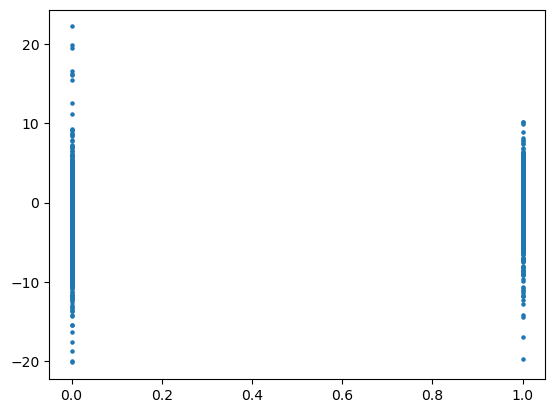

In [65]:
import matplotlib.pyplot as plt
plt.scatter(y, x, s=5)

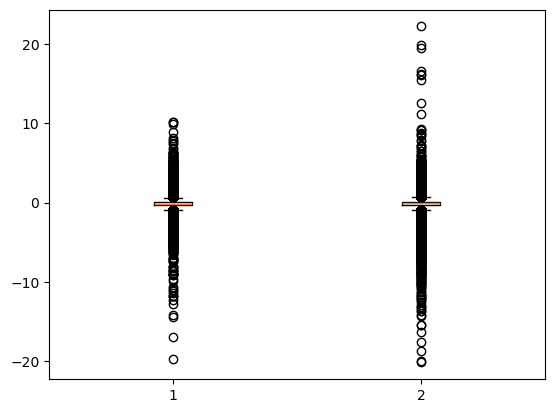

In [67]:
plt.boxplot([x[y], x[~y]]);
plt.xticks([s])